In [2]:
import numpy as np
import math as mt
from numpy.linalg import norm
import matplotlib.pyplot as plt
pi = mt.pi

In [17]:
n = 9
def GLC(n):
    x_gll = np.cos((pi*np.arange(n)) / (n-1))
    return x_gll

In [18]:
node = GLC(n)
node

array([ 1.00000000e+00,  9.23879533e-01,  7.07106781e-01,  3.82683432e-01,
        6.12323400e-17, -3.82683432e-01, -7.07106781e-01, -9.23879533e-01,
       -1.00000000e+00])

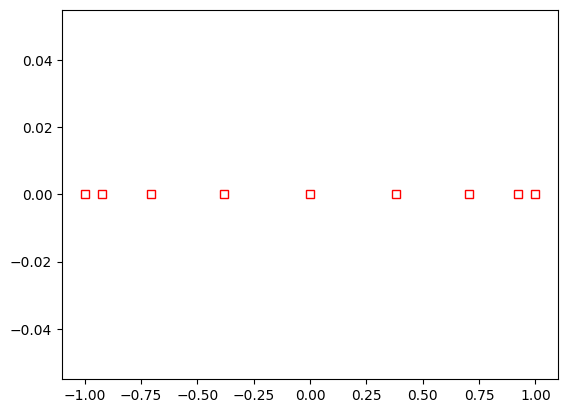

In [20]:
plt.plot(node, np.zeros(n), 'sr',mfc='none',label='GLC nodes')

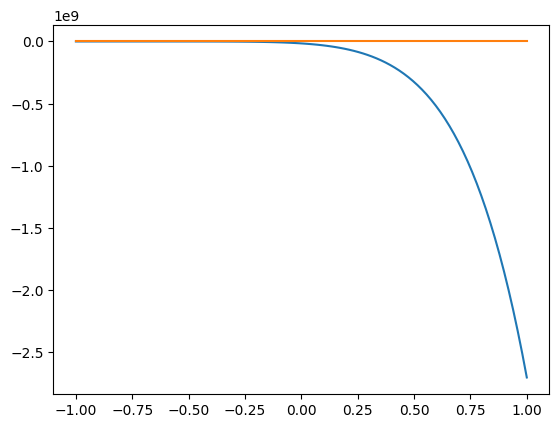

In [36]:
f = lambda x: (np.sin(20*(x-1*np.mean(x)))/(1+50.*(x-np.mean(x))**2.))
def Lagrange_polynomias(n, f, n_node):
    sum = 0.0
    x = np.arange(n)
    x_node = np.arange(n_node)
    f_node = f(x_node)
    f_inter = np.zeros(n)
    for i in range(n_node):
        prod = 1.0
        for j in range(n_node):
            if j!=i:
                temp = (x - x_node[j]) / (x_node[i] - x_node[j])
                prod = prod * temp
        f_inter = f_node[i]*prod + f_inter

    return f_inter

f_l = Lagrange_polynomias(100, f, 9)
x = np.linspace(-1.0, 1.0, 100)
plt.plot(x, f_l)
plt.plot(x, f(x))



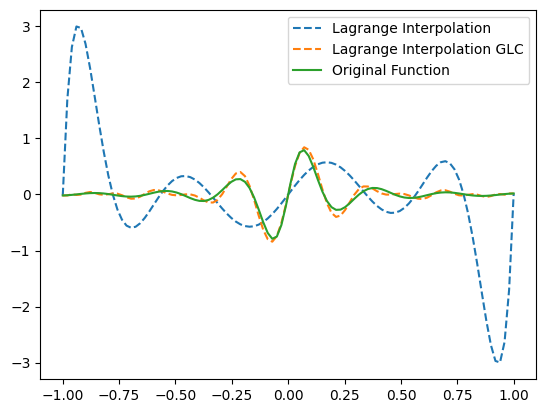

In [51]:
import numpy as np
import matplotlib.pyplot as plt

# Define function
f = lambda x: (np.sin(20 * (x - np.mean(x))) / (1 + 50.0 * (x - np.mean(x)) ** 2.0))

def Lagrange_polynomials(x, x_node, f_node):
    n = len(x)
    n_node = len(x_node)
    f_inter = np.zeros(n)
    
    for i in range(n_node):
        prod = 1.0
        for j in range(n_node):
            if j != i:
                # Use x_node instead of x for the basis polynomials
                temp = (x - x_node[j]) / (x_node[i] - x_node[j])
                prod = prod * temp
        f_inter += f_node[i] * prod
        
    return f_inter

x = np.linspace(-1.0, 1.0, 100)
x_node = np.linspace(-1.0, 1.0, 10)  
x_GLC = GLC(30)
f_node = f(x_node)
f_GLC = f(x_GLC)

f_l = Lagrange_polynomials(x, x_node, f_node)
f_l_GLC = Lagrange_polynomials(x, x_GLC, f_GLC)

# Plot results
plt.plot(x, f_l, label='Lagrange Interpolation', linestyle='--')
plt.plot(x, f_l_GLC, label='Lagrange Interpolation GLC', linestyle='--')
plt.plot(x, f(x), label='Original Function')
plt.legend()
plt.show()

In [59]:
def GLC_pts(N):
    """
    Gauss-Lobatto-Chebyshev Points
    args:
       `N`: int, order of the Chebyshev polynomial
    returns:
       numpy array of size N+1 containing the GLC points
    """
    return(np.cos(pi*np.arange(N+1)/N))

def chebyBase(k,x):
    """
    Chebyshev basis function
    args:
       `k`: int or a numpy array of int
          Order of the Chebyshev  polynomial
       `x`: numpy array
          points in the physical space
    returns:
       T_k(x): numpy array of size 
    """
    if (isinstance(k,np.ndarray)):
       cheb_=np.cos(np.dot(np.arccos(x),k.T))
    else:
       cheb_=np.cos(k*np.arccos(x))
    return cheb_

# Chebyshev interpolant using collocation method
def cheby_colloc(N,x,f,xTest):
    """
    1. Apply collocation method to compute Chebyshev coefficients
    2. Interpolate function f at `xTest` using Chebyshev bases
    args:
       'N': int, max polynomial order
       `x`: input x, 1d numpy array of size N+1
       `f`: input f at `x`, 1d numpy array of size N+1
       `xTest`: test points at which the approximate `f` is computed via Chebyshev interpolation
    returns:
       `fCheb`: approximate function values at `xTest`, 1d numpy array
    """
    #Coefficients for the Chebyshev expansion
    T=chebyBase(np.arange(N+1)[:,None],x[:,None])    
    a=np.dot(np.linalg.inv(T),f)
    #interpolation at test points
    fCheb=np.zeros(len(xTest))
    for k in range(N+1):
        Tkx=chebyBase(k,xTest)
        fCheb+=a[k]*Tkx
    return fCheb

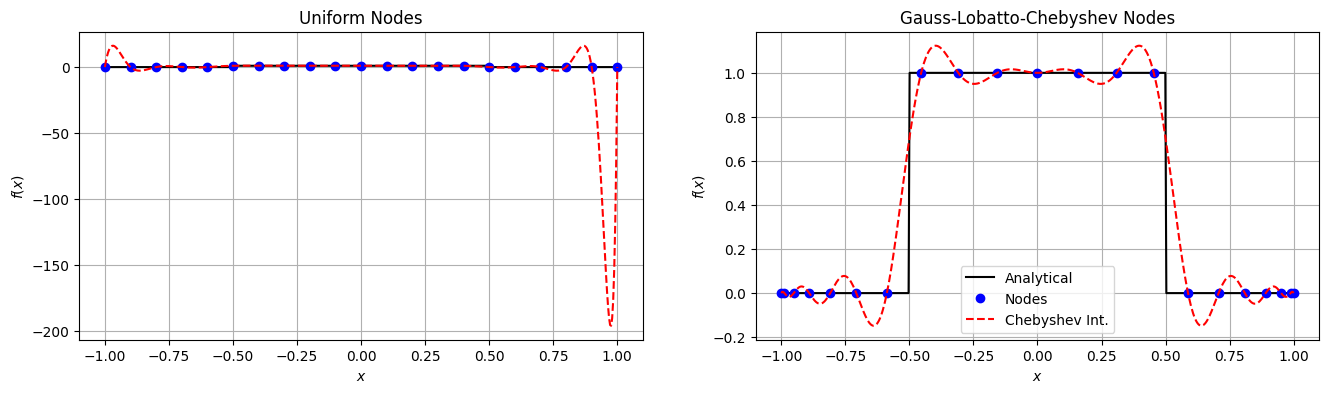

In [135]:
# define the analytical f(x)
f = lambda x: (1./(1+16*x**2.))
fp = lambda x: -32.*x/(1+16*x**2.)**2.  #f'(x)
f = lambda x: np.heaviside(x+0.5,1.)-np.heaviside(x-0.5,1)  

#---- Settings
N=20   #max poynomial order
#--------------------
n=N+1   #number of nodes

#generate data
xBound=[-1.,1.]
xUnif=np.linspace(xBound[0],xBound[1],n)
fUnif=f(xUnif)
xCL=GLC_pts(N)
fCL=f(xCL)
xTest=np.linspace(xBound[0],xBound[1],500)

#Collocation method to compute coefficients in the Chebyshev transform
fUnif_cheb=cheby_colloc(N,xUnif,fUnif,xTest)
fCL_cheb=cheby_colloc(N,xCL,fCL,xTest)

#plots
plt.figure(figsize=(16,4))
plt.subplot(1,2,1)
plt.plot(xTest,f(xTest),'-k')
plt.plot(xUnif,fUnif,'ob')
plt.plot(xTest,fUnif_cheb,'--r')
plt.xlabel(r'$x$')
plt.ylabel(r'$f(x)$')
plt.title('Uniform Nodes')
plt.grid()
#
plt.subplot(1,2,2)
plt.plot(xTest,f(xTest),'-k',label='Analytical')
plt.plot(xCL,fCL,'ob',label='Nodes')
plt.plot(xTest,fCL_cheb,'--r',label='Chebyshev Int.')
plt.xlabel(r'$x$')
plt.ylabel(r'$f(x)$')
plt.legend(loc='best')
plt.title('Gauss-Lobatto-Chebyshev Nodes')
plt.grid()
plt.show()



In [136]:
from numpy.linalg import norm

def compare(N):

    #--------------------
    n=N+1   #number of nodes
    
    #generate data
    xBound=[-1.,1.]
    xUnif=np.linspace(xBound[0],xBound[1],n)
    fUnif=f(xUnif)
    xCL=GLC_pts(N)
    fCL=f(xCL)
    xTest=np.linspace(xBound[0],xBound[1],500)
    f_anal = f(xTest)
    
    # #Collocation method to compute coefficients in the Chebyshev transform
    fUnif_cheb=cheby_colloc(N,xUnif,fUnif,xTest)
    fCL_cheb=cheby_colloc(N,xCL,fCL,xTest)
    
    # err_CL = norm((f_anal-fCL_cheb,np.inf))/norm(f_anal,np.inf)
    # err_unif = norm((f_anal-fUnif, np.inf))/norm(f_anal,np.inf)
    # return err_CL, err_unif
    return norm(f_anal - fCL_cheb, np.inf) / norm(f_anal,np.inf), norm(f_anal-fUnif_cheb,np.inf) / norm(f_anal,np.inf)


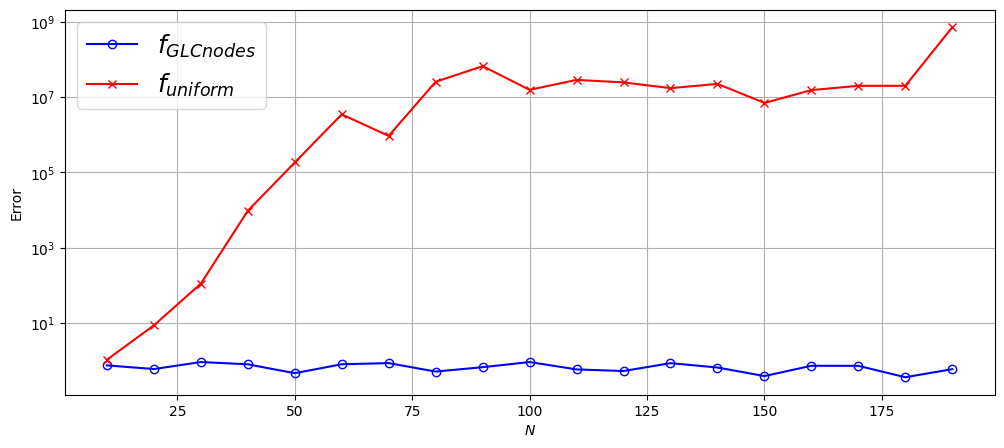

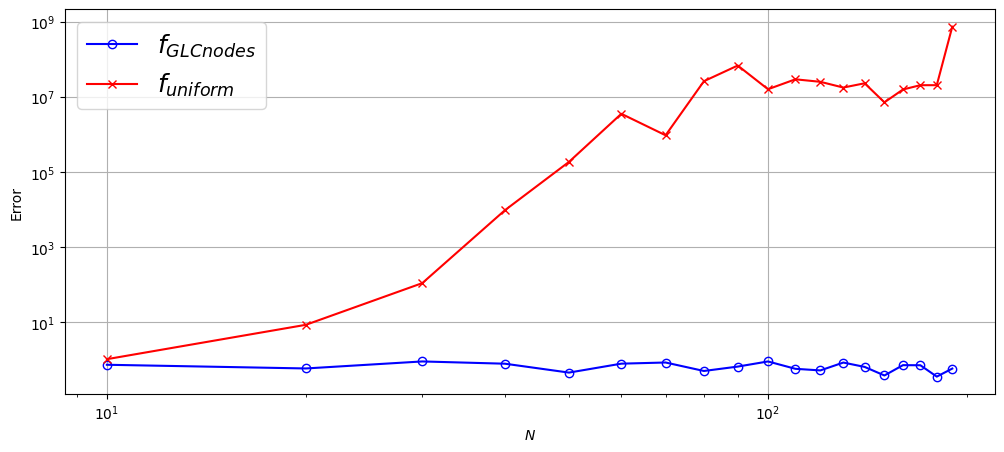

In [137]:
error1=[] #error in f'(x)
error2=[] #error in f''(x)
N=[]   
f = lambda x: np.heaviside(x-0.75,1.)-np.heaviside(x-2.25,1)  

for N_ in range(10, 200, 10):
    err1,err2=compare(N_)
    error1.append(err1)
    error2.append(err2)
    N.append(N_)

#plot
plt.figure(figsize=(12,5))
plt.semilogy(N,error1,'-ob',mfc='none',label=r'$f_{GLC nodes}$')
plt.plot(N,error2,'-xr',mfc='none',label=r'$f_{uniform}$')
plt.xlabel(r'$N$')
plt.ylabel('Error')
plt.grid()
plt.legend(loc='best',fontsize=18)
plt.show()
#plot
plt.figure(figsize=(12,5))
plt.loglog(N,error1,'-ob',mfc='none',label=r'$f_{GLC nodes}$')
plt.loglog(N,error2,'-xr',mfc='none',label=r'$f_{uniform}$')
plt.xlabel(r'$N$')
plt.ylabel('Error')
plt.grid()
plt.legend(loc='best',fontsize=18)
plt.show()



In [153]:
import numpy as np
from scipy.linalg import toeplitz

def chebdif(N, M):
    """Chebyshev-Gauss-Lobatto nodes x_k = cos(k*pi/(N-1)) (x[0]=1, x[-1]=-1)
       and DM[m-1] = m-th derivative matrix acting on nodal values."""
    I = np.eye(N, dtype=bool)
    n1, n2 = N//2, int(np.ceil(N/2))
    k = np.arange(N)
    th = k*np.pi/(N-1)
    x = np.sin(np.pi*np.arange(N-1, -N, -2)/(2*(N-1)))
    T = np.tile(th/2, (N, 1)).T
    DX = 2*np.sin(T.T + T)*np.sin(T.T - T)
    DX = np.vstack([DX[:n1], -np.flipud(np.fliplr(DX[:n2]))])
    DX[I] = 1.0
    Cm = toeplitz((-1.0)**k)
    Cm[0, :] *= 2; Cm[-1, :] *= 2; Cm[:, 0] /= 2; Cm[:, -1] /= 2
    Z = 1.0/DX; Z[I] = 0.0
    D = np.eye(N); DM = np.empty((M, N, N))
    for ell in range(1, M+1):
        D = ell*Z*(Cm*np.tile(np.diag(D)[:, None], (1, N)) - D)
        D[I] = -D.sum(axis=1)
        DM[ell-1] = D
    return x, DM

In [187]:
Re = 10000    # Re_cl
alpha=1.12   # streamwise wavenumber
N=200        # resolution

In [188]:
y,D_=chebdif(N,1)
D=D_[0,:,:]
D2=D@D
D4=D2@D2

In [189]:
# A*vhat = omega*B*vhat
I = np.identity(N)
A = -(D4-2*D2*alpha**2+I*alpha**4)/Re + 2j*alpha*I + 1j*alpha*np.diag(1-y**2)@(D2-I*alpha**2)
B = 1j*(D2-I*alpha**2)


In [190]:
# move the eigenvalues of the BC to Q
Q=-999j
# two homogeneous Dirichlet conditions
A[0,:] = Q*I[0,:]
B[0,:] = I[0,:]
A[-1,:] = Q*I[-1,:]
B[-1,:] = I[-1,:]

B[-1,-5:]

array([0.+0.j, 0.+0.j, 0.+0.j, 0.+0.j, 1.+0.j])

In [191]:
# two homogeneous Neumann conditions
A[1,:] = Q*D[0,:]
B[1,:] = D[0,:]
A[-2,:] = Q*D[-1,:]
B[-2,:] = D[-1,:]

In [192]:
# compute eigenvalues and eigenvectors (A*vhat = omega*B*vhat)
omega,vv = scla.eig(A,B)
c=omega/alpha

In [193]:
i=np.argmax(c.imag)
cmax = c[i]

v=vv[:,i]
u=-np.dot(D,v)/(1j*alpha)  # use continuity equation i alpha u + Dv = 0

print('Leading eigenvalue c = ',cmax)

Leading eigenvalue c =  (0.24854038117492946-0.001515788635885558j)


In [200]:
i=np.argmax(abs(u))
w=u[i]
u/=w
v/=w


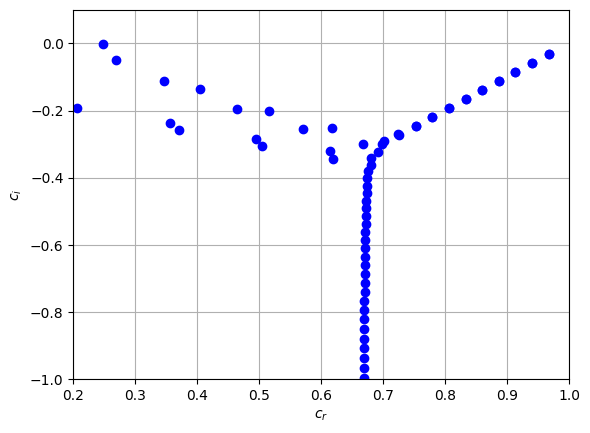

In [201]:
#plt.figure()
plt.plot(c.real,c.imag,'ob')
plt.xlim([0.2,1])
plt.ylim([-1,0.1])
plt.grid()
plt.xlabel('$c_r$')
plt.ylabel('$c_i$')
plt.show()

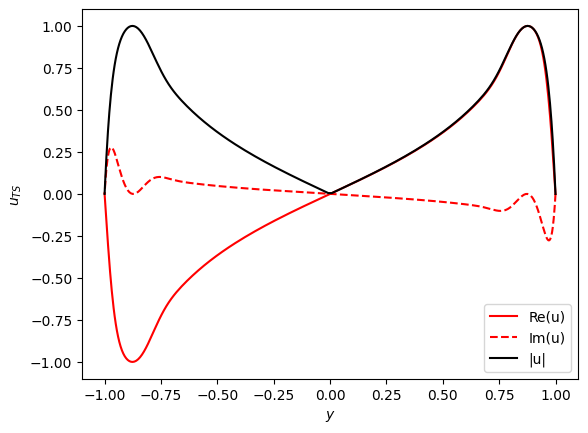

In [186]:
#plt.figure()
plt.plot(y,u.real,'r',label='Re(u)')
plt.plot(y,u.imag,'r--',label='Im(u)')
plt.plot(y,abs(u),'k-',label='|u|')
plt.legend(loc='best')
plt.xlabel(r'$y$')
plt.ylabel(r'$u_{TS}$')
plt.show()

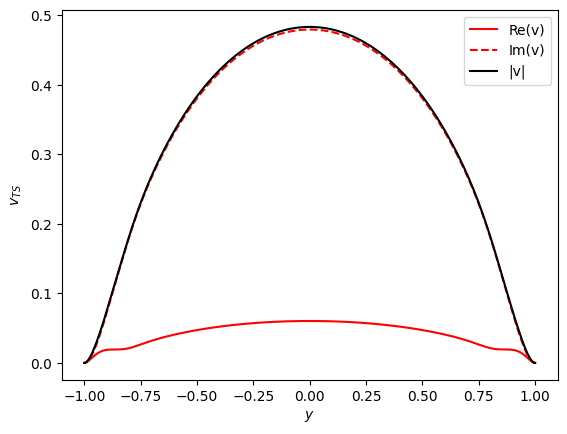

In [173]:
#plt.figure()
plt.plot(y,v.real,'r',label='Re(v)')
plt.plot(y,v.imag,'r--',label='Im(v)')
plt.plot(y,abs(v),'k-',label='|v|')
plt.xlabel(r'$y$')
plt.ylabel(r'$v_{TS}$')
plt.legend(loc='best')
plt.show()

In [174]:
N_Re=21
N_alpha=20
RE,ALPHA = np.meshgrid(np.linspace(1000,40000,N_Re),np.linspace(0.5,1.2,N_alpha))

In [175]:
g=np.zeros((N_Re,N_alpha))
for ii in range(N_Re):
    for jj in range(N_alpha):
        Re=RE[jj,ii]
        alpha=ALPHA[jj,ii]
        A = -(D4-2*D2*alpha**2+I*alpha**4)/Re + 2j*alpha*I + 1j*alpha*np.diag(1-y**2)@(D2-I*alpha**2)
        B = 1j*(D2-I*alpha**2)

        Q=-999j
        A[0,:] = Q*I[0,:]
        B[0,:] = I[0,:]
        A[-1,:]  = Q*I[-1,:]
        B[-1,:] = I[-1,:]
        A[1,:] = Q*D[0,:]
        B[1,:] = D[0,:]
        A[-2,:] = Q*D[-1,:]
        B[-2,:] = D[-1,:]
        
        omega,vv = scla.eig(A,B)
        g[ii,jj]=np.max(omega.imag)

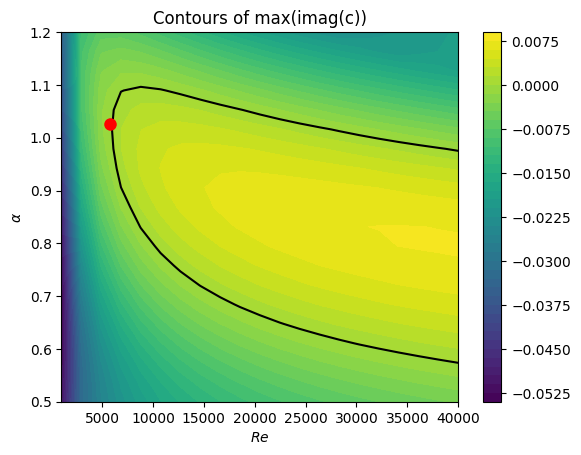

In [203]:
#plt.figure()
CS=plt.contourf(RE[0,:],ALPHA[:,0],g.T,levels=40)
plt.colorbar()
CS1=plt.contour(RE[0,:],ALPHA[:,0],g.T,levels=[0],colors='k')
plt.title('Contours of max(imag(c))')
plt.xlabel(r'$Re$')
plt.ylabel(r'$\alpha$')
plt.plot(5772,1.0255,'ro',ms=8) # Orszag 1971
plt.show()


In [204]:
"""2D incompressible Navier-Stokes, vorticity form, doubly periodic.
Pseudo-spectral (rfft2), 2/3 dealiasing, ETDRK2 time stepping.
Convention: omega = -lap(psi), u = psi_y, v = -psi_x.
State is kept in spectral space (w_hat, shape (Nx, Ny//2+1)).
"""
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp


def make_grid(Nx, Ny, Lx, Ly):
    kx = jnp.fft.fftfreq(Nx, Lx / (Nx * 2 * jnp.pi))
    ky = jnp.fft.rfftfreq(Ny, Ly / (Ny * 2 * jnp.pi))
    KX, KY = jnp.meshgrid(kx, ky, indexing="ij")
    mask = (jnp.abs(KX) <= (2 / 3) * jnp.max(jnp.abs(kx))) & \
           (jnp.abs(KY) <= (2 / 3) * jnp.max(jnp.abs(ky)))
    mask = mask.astype(jnp.float64)    # float, not bool: JAX can't negate a bool array
    x =jnp.linspace(0, Lx, Nx, endpoint=False)
    y = jnp.linspace(0, Ly, Ny, endpoint=False)
    X, Y = jnp.meshgrid(x, y, indexing="ij")
    return X, Y, KX, KY, mask


def make_stepper(Nx, Ny, Lx, Ly, nu, dt, forcing_hat=None):
    X, Y, KX, KY, mask = make_grid(Nx, Ny, Lx, Ly)
    K2 = KX**2 + KY**2
    inv_K2 = jnp.where(K2 == 0, 0.0, 1.0 / jnp.where(K2 == 0, 1.0, K2))

    # ETD coefficients: phi1 = (e^x-1)/x, phi2 = (e^x-1-x)/x^2, x = c*dt
    x = -nu * K2 * dt
    E = jnp.exp(x)
    small = jnp.abs(x) < 1e-4
    xs = jnp.where(small, 1.0, x)
    phi1 = jnp.where(small, 1 + x / 2 + x**2 / 6, jnp.expm1(xs) / xs)
    phi2 = jnp.where(small, 0.5 + x / 6 + x**2 / 24, (jnp.expm1(xs) - xs) / xs**2)

    f_hat = 0.0 if forcing_hat is None else forcing_hat
    irfft = lambda a: jnp.fft.irfft2(a, s=(Nx, Ny))

    def velocity_hat(w_hat):
        psi_hat = w_hat * inv_K2
        return 1j * KY * psi_hat, -1j * KX * psi_hat

    def nonlinear(w_hat):
        u_hat, v_hat = velocity_hat(w_hat)
        u, v = irfft(u_hat), irfft(v_hat)
        wx, wy = irfft(1j * KX * w_hat), irfft(1j * KY * w_hat)
        return -mask * jnp.fft.rfft2(u * wx + v * wy) + f_hat

    def step(w_hat):
        N0 = nonlinear(w_hat)
        a = E * w_hat + dt * phi1 * N0
        return a + dt * phi2 * (nonlinear(a) - N0)

    grid = dict(X=X, Y=Y, KX=KX, KY=KY, mask=mask, inv_K2=inv_K2,
                velocity_hat=velocity_hat, irfft=irfft)
    return step, grid


def integrate(step, w_hat, n_steps):
    return jax.lax.fori_loop(0, n_steps, lambda _, w: step(w), w_hat)


def energy_enstrophy(w_hat, inv_K2, Nx, Ny):
    # Parseval with rfft half-plane weights (ky=0 and Nyquist columns counted once)
    wgt = jnp.full(w_hat.shape, 2.0).at[:, 0].set(1.0)
    if Ny % 2 == 0:
        wgt = wgt.at[:, -1].set(1.0)
    p = wgt * jnp.abs(w_hat)**2 / (Nx * Ny)**2
    return 0.5 * jnp.sum(p * inv_K2), 0.5 * jnp.sum(p)

In [240]:
Nx = Ny = 64
Lx = Ly = 2 * jnp.pi
Re, n = 40.0, 4
dt, t_end = 0.005, 500.0
n_steps = int(round(t_end / dt))

X, Y, KX, KY, mask = make_grid(Nx, Ny, Lx, Ly)

forcing_hat = mask * jnp.fft.rfft2(-n * jnp.cos(n * Y))
step, grid = make_stepper(Nx, Ny, Lx, Ly, 1.0 / Re, dt, forcing_hat=forcing_hat)

w_lam = -(Re / n) * jnp.cos(n * Y)
noise = 1e-2 * jax.random.normal(jax.random.PRNGKey(0), (Nx, Ny))
w0_hat = mask * jnp.fft.rfft2(w_lam + noise)

run = jax.jit(integrate, static_argnums=(0, 2))   # step and n_steps are fixed at compile time
w_hat_end = run(step, w0_hat, n_steps)

omega_end = grid["irfft"](w_hat_end) 

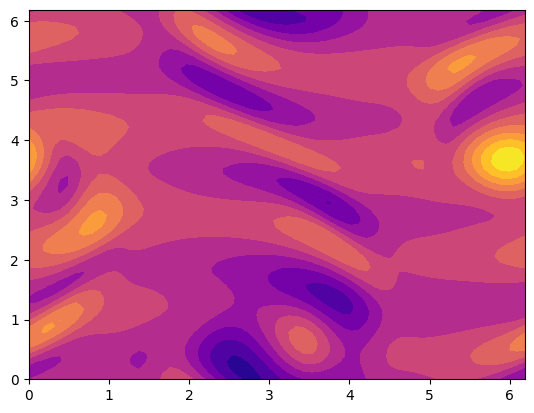

In [241]:
plt.contourf(X, Y, omega_end, levels = 10, cmap = 'plasma')
plt.show()